In [11]:
import json
from pathlib import Path
import pandas as pd

In [12]:
raw_dir = Path("../data/raw")
latest = {}
for f in sorted(raw_dir.glob("*/*.json")):
    latest[f.name.split("_")[0]] = f
latest

{'birmingham': WindowsPath('../data/raw/2026-11-19/birmingham_20261119T133201.json'),
 'cardiff': WindowsPath('../data/raw/2026-11-19/cardiff_20261119T133203.json'),
 'edinburgh': WindowsPath('../data/raw/2026-11-19/edinburgh_20261119T133202.json'),
 'london': WindowsPath('../data/raw/2026-11-19/london_20261119T133200.json'),
 'manchester': WindowsPath('../data/raw/2026-11-19/manchester_20261119T133201.json')}

In [13]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

frames = []
for city, f in latest.items():
    with open(f, encoding="utf-8") as fh:
        frames.append(flatten(json.load(fh), city.title()))

df = pd.concat(frames, ignore_index=True)
df.shape

(240, 10)

In [14]:
print(df.shape)
print(df.dtypes)
df.head()

(240, 10)
time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
dtype: object


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-18T00:00,8.0,86,5.5,0.0,9.7,3,Birmingham,52.488224,-1.909378
1,2026-11-18T01:00,7.6,95,5.0,1.0,12.2,55,Birmingham,52.488224,-1.909378
2,2026-11-18T02:00,7.8,92,5.7,1.0,8.3,55,Birmingham,52.488224,-1.909378
3,2026-11-18T03:00,7.7,93,5.4,0.0,10.4,3,Birmingham,52.488224,-1.909378
4,2026-11-18T04:00,7.6,95,5.0,0.0,11.9,3,Birmingham,52.488224,-1.909378


In [15]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
dtype: int64

In [16]:
df.describe()

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,7.995000,86.745833,5.638333,0.230000,9.282083,24.795833,52.983542,-2.133569
std,1.848978,9.663696,2.172602,0.489402,4.639846,24.893497,1.663127,1.128787
min,4.200000,60.000000,0.800000,0.000000,1.100000,0.000000,51.480080,-3.206848
25%,6.600000,81.000000,4.075000,0.000000,5.700000,3.000000,51.511470,-3.192810
50%,7.600000,91.000000,5.600000,0.000000,8.600000,3.000000,52.488224,-2.228027
75%,9.200000,94.000000,7.200000,0.200000,12.200000,51.000000,53.478767,-1.909378
max,12.900000,98.000000,10.300000,2.900000,25.900000,63.000000,55.959167,-0.130783


In [17]:
dups = df.duplicated(subset=["city", "time"]).sum()
print("Duplicate (city, time):", dups)

Duplicate (city, time): 0


In [18]:
all_frames = []
for f in sorted(raw_dir.glob("*/*.json")):
    with open(f, encoding="utf-8") as fh:
        all_frames.append(flatten(json.load(fh), f.name.split("_")[0].title()))
df_all = pd.concat(all_frames, ignore_index=True)
print(df_all.shape)
print("Duplicate (city, time):", df_all.duplicated(subset=["city", "time"]).sum())

(1152, 10)
Duplicate (city, time): 912


In [19]:
df["weather_code"].value_counts().sort_index()

weather_code
0       2
1       3
2      17
3     112
51     70
53     21
55      4
61      9
63      2
Name: count, dtype: int64

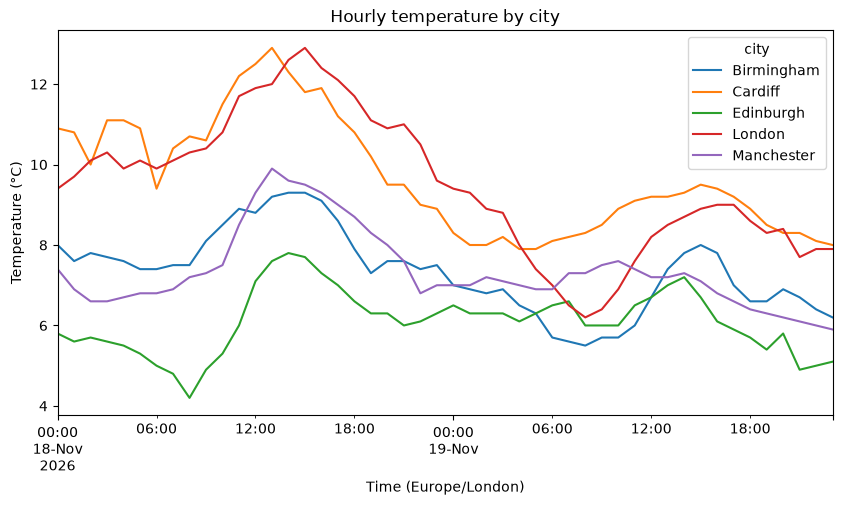

In [20]:
import matplotlib.pyplot as plt

df["time"] = pd.to_datetime(df["time"])
pivot = df.pivot(index="time", columns="city", values="temperature_2m")

ax = pivot.plot(figsize=(10, 5))
ax.set_xlabel("Time (Europe/London)")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Hourly temperature by city")
plt.show()

## Findings

1. **`time` loads as text, not datetime.** It must be converted with `pd.to_datetime` before sorting or plotting. I did this before the chart.
2. **No nulls.** Every column has 240 values (5 cities × 48 hours), so no imputation is needed for this sample.
3. **Values are realistic for a UK November.** Temperature ranges 4.2–12.9 °C (mean about 8 °C) and humidity 60–98% (mean about 87%).
4. **Weather is mostly overcast or drizzly.** Of 240 rows, code 3 (overcast) appears 112 times and drizzle codes 51/53/55 appear 95 times; clear sky (code 0) only twice.
5. **Overlapping files create duplicates.** Loading all raw files gives 1,152 rows, of which 912 are duplicate `(city, time)` pairs, because running `extract.py` several times saved the same hours again. Using only the latest file per city gives 0 duplicates. A proper deduplication rule will be built in Task 1.5.